In [1]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Secara defalt, make_classfication menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[136 143]
 [157 133]
 [ 72  56]
 [  9  57]
 [161 126]
 [ 73  49]
 [183 149]
 [111 138]
 [ 83 181]
 [ 18   6]
 [ 91  91]
 [ 87  97]
 [ 32 180]
 [ 94  76]
 [113  87]
 [102  49]
 [281 280]
 [ 78  43]
 [ 61  45]
 [  9  43]
 [229 289]
 [234 244]
 [ 36  15]
 [108  54]
 [ 26  89]
 [  9  40]
 [ 42  59]
 [ 96 101]
 [133 143]
 [123 106]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [2]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,136,143,0
1,157,133,0
2,72,56,0
3,9,57,0
4,161,126,0


In [3]:
# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,136,143,Kelas B
1,157,133,Kelas B
2,72,56,Kelas B
3,9,57,Kelas B
4,161,126,Kelas B


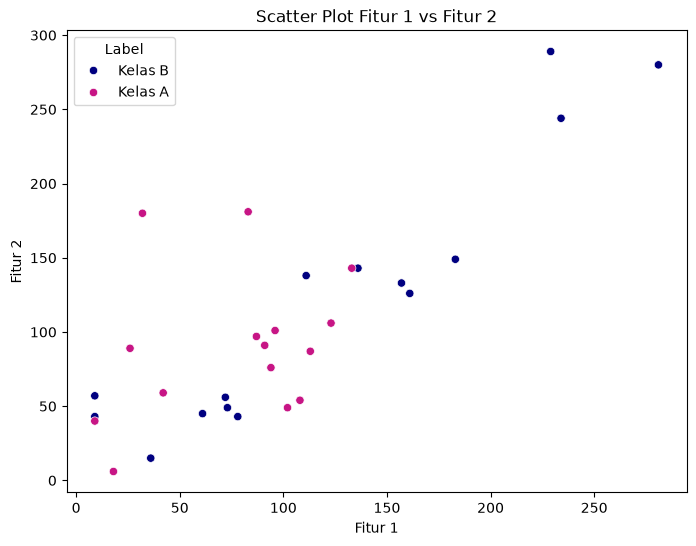

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Langsung pakai DataFrame df_label, pastikan palet warnanya mencakup nilai 0 dan 1
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_label, 
    x='Fitur 1', 
    y='Fitur 2', 
    hue='Label', # Karena kolom Label sudah di-map jadi 'Kelas A' & 'Kelas B' (atau kalau mau aman pakai kolom aslinya)
    palette={'Kelas A': 'MediumVioletRed', 'Kelas B': 'Navy'}
)
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Scatter Plot Fitur 1 vs Fitur 2')
plt.show()

In [9]:
from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi
	
# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()
	
# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy
	
# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)
	
# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)
	
# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)
	
# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)
	
# Prediksi test data
y_test_pred = mnb.predict(X_test)
	
# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)
	
# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.47619047619047616
Hasil akurasi data test: 0.5555555555555556


In [10]:
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6666666666666666
Hasil akurasi data test (Gaussian): 0.6666666666666666
